# Held-out validation of the v1 knobs

v1's Layer-D knobs — **θ_in 8%, θ_keep 2%, EWMA halflife 7d** — were chosen on the 5 majors over the
whole 2021–2026 sample, so their headline (net 9.4%, Sharpe 6.4) is potentially overfit on both time
and names. We re-derive the knobs by a **gated** sweep on a *tuning* set (max net Sharpe among knobs
with net APR>0 and still >0 at 2× cost) and score the SAME knobs out-of-sample on two axes:

- **Temporal** — tune on majors 2021–2023, test on majors 2024–2026.
- **Cross-sectional** — tune on the majors, apply unchanged to the ~461 other tradeable names.

The decision/booking is the exact production path (`lab.evaluate` reproduces `engine.run` to
1e-6; checked below). The money chart is the **train-vs-test Sharpe scatter**: if high-train knobs
sit below the diagonal out-of-sample, the tuning was fitting noise.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
import sys; from pathlib import Path
_p = Path.cwd().resolve()
ROOT = next((q for q in [_p, *_p.parents] if (q/'pyproject.toml').exists()), _p)
sys.path[:0] = [str(ROOT)]
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import research.funding_carry.lab as H
from src.common import config as cfg
plt.rcParams.update({'figure.figsize':(14,3.8),'axes.grid':True,'grid.alpha':0.25,
                     'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
NAVY,TEAL,AMBER,RED,GREY='#1f3a5f','#2a9d8f','#e0a32e','#c1121f','0.6'
INC = H.INCUMBENT                                  # the v1 defaults we're testing
COSTS = cfg.load_config('strategies/funding_carry/v1.yaml')['costs']

par = H.validate_engine()
print('engine parity:', 'OK' if par['ok'] else 'MISMATCH', '|', par['compare'])
maj, non = H.universe()
print(f'universe: {len(maj)} majors, {len(non)} non-majors  (all 3 legs present)')
Pmaj = H.load_panels(maj); Pnon = H.load_panels(non)
DID = Pmaj['didx']
def m(start=None,end=None): return H._window_mask(DID, start, end)
def mn(start=None,end=None): return H._window_mask(Pnon['didx'], start, end)
print('panels:', Pmaj['F'].shape, Pnon['F'].shape)

2026-07-01 16:06:17,879 INFO     funding_carry.engine | funding_carry v1: net@1x ann=9.41% sharpe=6.41 turnover=9.1x (C:\Users\SamuelAhou\Documents\operator\results\funding_carry\v1\20260701T140617Z)


engine parity: OK | {'ann_return': (0.0941, 0.0941), 'sharpe': (6.406, 6.406), 'ann_turnover': (9.1, 9.1)}


universe: 5 majors, 461 non-majors  (all 3 legs present)


panels: (1977, 5) (1977, 461)


## Axis 1 — temporal (majors)

Sweep the grid on **2021–2023** (train), pick the gated-best, and read it — plus the **incumbent**
— on **2024–2026** (test). A knob set that only worked in-sample will show a train→test collapse.

In [2]:
SPLIT='2023-12-31'
sw_tr = H.sweep(Pmaj, COSTS, mask=m(end=SPLIT))
sel = H.select(sw_tr)
BEST_T = {k: sel[k] for k in ('ewma_halflife','theta_in_apr','theta_keep_apr')}
print('gated-best on majors 2021-2023:', BEST_T, '| gate satisfied:', sel['gated'])
print('incumbent:', INC)

def kpi(panels, knob, mask, warm=14):
    r = H.evaluate(panels, knob['ewma_halflife'], knob['theta_in_apr'], knob['theta_keep_apr'],
                   COSTS, mask=mask, warmup_days=warm)
    a,b = r['1.0x'], r['2.0x']
    return {'net_apr%':round(a['ann_return']*100,2),'net_apr_2x%':round(b['ann_return']*100,2),
            'sharpe':a['sharpe'],'sharpe_2x':b['sharpe'],'gross_apr%':round(a['gross_ann_return']*100,2),
            'max_dd%':round(a['max_drawdown']*100,1),'turnover':a['ann_turnover'],
            'pct_deployed':a['pct_days_deployed'],'avg_names':a['avg_names_held']}, r

rows={}
for lab,knob,msk in [('incumbent · train',INC,m(end=SPLIT)),('incumbent · TEST',INC,m(start='2024-01-01')),
                     ('best_T · train',BEST_T,m(end=SPLIT)),('best_T · TEST',BEST_T,m(start='2024-01-01'))]:
    rows[lab],_ = kpi(Pmaj,knob,msk)
print(); print(pd.DataFrame(rows).T.to_string())

gated-best on majors 2021-2023: {'ewma_halflife': 10, 'theta_in_apr': 0.1, 'theta_keep_apr': 0.0} | gate satisfied: True
incumbent: {'ewma_halflife': 7, 'theta_in_apr': 0.08, 'theta_keep_apr': 0.02}

                   net_apr%  net_apr_2x%  sharpe  sharpe_2x  gross_apr%  max_dd%  turnover  pct_deployed  avg_names
incumbent · train     12.33        10.17   6.725      4.822       14.50     -2.4      11.4         0.734       3.44
incumbent · TEST       5.83         4.64   7.404      4.285        7.02     -0.5       6.2         0.755       3.10
best_T · train        14.55        13.93   8.373      7.708       15.18     -0.7       3.3         0.940       2.78
best_T · TEST          6.81         6.25   9.641      7.377        7.36     -0.5       2.9         0.906       3.19


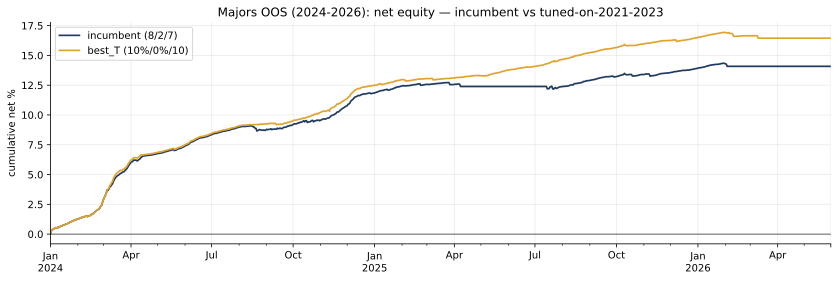

In [3]:
# Net equity on the TEST window (majors 2024-2026): incumbent vs tuned-best
fig, ax = plt.subplots(figsize=(14,4))
for lab,knob,c in [('incumbent (8/2/7)',INC,NAVY),
                   (f"best_T ({BEST_T['theta_in_apr']:.0%}/{BEST_T['theta_keep_apr']:.0%}/{BEST_T['ewma_halflife']})",BEST_T,AMBER)]:
    _,r = kpi(Pmaj,knob,m(start='2024-01-01'))
    (r['net'].cumsum()*100).plot(ax=ax, color=c, lw=1.7, label=lab)
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %')
ax.legend(); ax.set_title('Majors OOS (2024-2026): net equity — incumbent vs tuned-on-2021-2023')
plt.show()

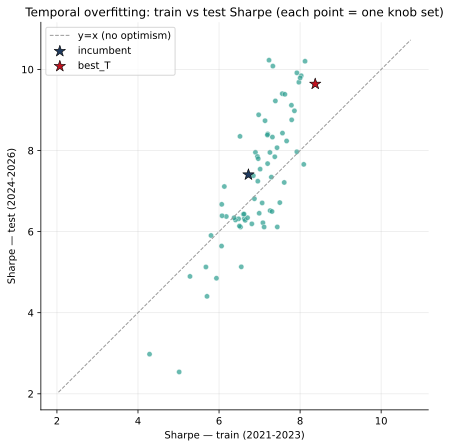

corr(train,test) Sharpe = 0.83  (low/negative = tuning picks up noise; high = signal generalizes across time)


In [4]:
# Overfitting scatter: each knob combo's Sharpe on train (2021-23) vs test (2024-26)
sw_te = H.sweep(Pmaj, COSTS, mask=m(start='2024-01-01'))
key=['hl','theta_in','theta_keep']
mrg = sw_tr.merge(sw_te, on=key, suffixes=('_tr','_te'))
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(mrg['sharpe_tr'], mrg['sharpe_te'], s=28, color=TEAL, alpha=0.7, edgecolor='w', lw=0.5)
lim=[min(mrg['sharpe_tr'].min(),mrg['sharpe_te'].min())-0.5, max(mrg['sharpe_tr'].max(),mrg['sharpe_te'].max())+0.5]
ax.plot(lim,lim,color=GREY,ls='--',lw=1,label='y=x (no optimism)')
for lab,knob,c in [('incumbent',INC,NAVY),('best_T',BEST_T,RED)]:
    q=mrg[(mrg.hl==knob['ewma_halflife'])&(np.isclose(mrg.theta_in,knob['theta_in_apr']))&(np.isclose(mrg.theta_keep,knob['theta_keep_apr']))]
    if len(q): ax.scatter(q['sharpe_tr'],q['sharpe_te'],s=140,color=c,marker='*',zorder=5,label=lab,edgecolor='k',lw=0.6)
ax.set_xlabel('Sharpe — train (2021-2023)'); ax.set_ylabel('Sharpe — test (2024-2026)')
ax.legend(); ax.set_title('Temporal overfitting: train vs test Sharpe (each point = one knob set)')
ax.set_aspect('equal'); plt.show()
print(f"corr(train,test) Sharpe = {mrg['sharpe_tr'].corr(mrg['sharpe_te']):.2f}  "
      f"(low/negative = tuning picks up noise; high = signal generalizes across time)")

## Axis 2 — cross-sectional (majors → the other ~461 names)

Tune on the majors (full period), then apply the knobs **unchanged** to the 461 non-major names —
the real test, since the strategy will run on the full universe. Expect a lower Sharpe: the majors
are unusually clean carry; the long tail is noisier and churns more.

In [5]:
sw_maj = H.sweep(Pmaj, COSTS)                    # majors, full period
selC = H.select(sw_maj); BEST_C={k:selC[k] for k in ('ewma_halflife','theta_in_apr','theta_keep_apr')}
print('gated-best on majors (full):', BEST_C, '| gate:', selC['gated'])
rows={}
for lab,knob,panels,msk in [
    ('incumbent · majors',INC,Pmaj,m()),('incumbent · NON-MAJORS',INC,Pnon,mn()),
    ('best_C · majors',BEST_C,Pmaj,m()),('best_C · NON-MAJORS',BEST_C,Pnon,mn())]:
    rows[lab],_ = kpi(panels,knob,msk)
print(); print(pd.DataFrame(rows).T.to_string())

gated-best on majors (full): {'ewma_halflife': 10, 'theta_in_apr': 0.1, 'theta_keep_apr': 0.0} | gate: True

                        net_apr%  net_apr_2x%  sharpe  sharpe_2x  gross_apr%  max_dd%  turnover  pct_deployed  avg_names
incumbent · majors          9.41         7.69   6.406      4.440       11.14     -2.4       9.1         0.743       3.28
incumbent · NON-MAJORS     16.27        13.36   1.567      1.284       19.18     -9.8      15.3         1.000     119.19
best_C · majors            11.07        10.48   7.975      7.130       11.67     -0.7       3.1         0.925       2.96
best_C · NON-MAJORS        20.73        19.06   1.120      1.029       22.40    -25.4       8.8         1.000     105.56


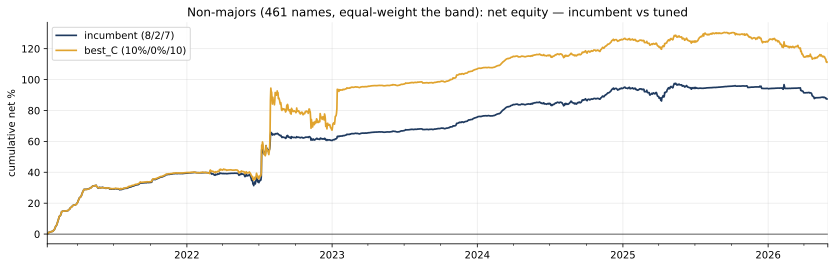

In [6]:
# Net equity on the 461 non-majors: incumbent vs cross-sectional-best (gross+net context)
fig, ax = plt.subplots(figsize=(14,4))
for lab,knob,c in [('incumbent (8/2/7)',INC,NAVY),
                   (f"best_C ({BEST_C['theta_in_apr']:.0%}/{BEST_C['theta_keep_apr']:.0%}/{BEST_C['ewma_halflife']})",BEST_C,AMBER)]:
    _,r = kpi(Pnon,knob,mn())
    (r['net'].cumsum()*100).plot(ax=ax, color=c, lw=1.7, label=lab)
ax.axhline(0,color='k',lw=0.6); ax.set_ylabel('cumulative net %')
ax.legend(); ax.set_title('Non-majors (461 names, equal-weight the band): net equity — incumbent vs tuned')
plt.show()

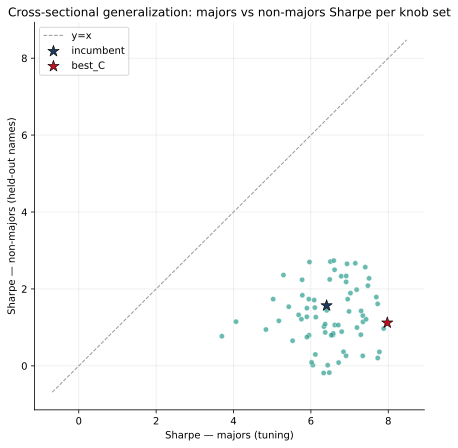

corr(majors,non-majors) Sharpe = 0.06


In [7]:
# Cross-sectional overfitting scatter: knob Sharpe on majors vs on non-majors
sw_nonf = H.sweep(Pnon, COSTS)
mrg2 = sw_maj.merge(sw_nonf, on=key, suffixes=('_maj','_non'))
fig, ax = plt.subplots(figsize=(7,7))
ax.scatter(mrg2['sharpe_maj'], mrg2['sharpe_non'], s=28, color=TEAL, alpha=0.7, edgecolor='w', lw=0.5)
lim=[min(mrg2['sharpe_maj'].min(),mrg2['sharpe_non'].min())-0.5, mrg2['sharpe_maj'].max()+0.5]
ax.plot(lim,lim,color=GREY,ls='--',lw=1,label='y=x')
for lab,knob,c in [('incumbent',INC,NAVY),('best_C',BEST_C,RED)]:
    q=mrg2[(mrg2.hl==knob['ewma_halflife'])&(np.isclose(mrg2.theta_in,knob['theta_in_apr']))&(np.isclose(mrg2.theta_keep,knob['theta_keep_apr']))]
    if len(q): ax.scatter(q['sharpe_maj'],q['sharpe_non'],s=140,color=c,marker='*',zorder=5,label=lab,edgecolor='k',lw=0.6)
ax.set_xlabel('Sharpe — majors (tuning)'); ax.set_ylabel('Sharpe — non-majors (held-out names)')
ax.legend(); ax.set_title('Cross-sectional generalization: majors vs non-majors Sharpe per knob set')
plt.show()
print(f"corr(majors,non-majors) Sharpe = {mrg2['sharpe_maj'].corr(mrg2['sharpe_non']):.2f}")

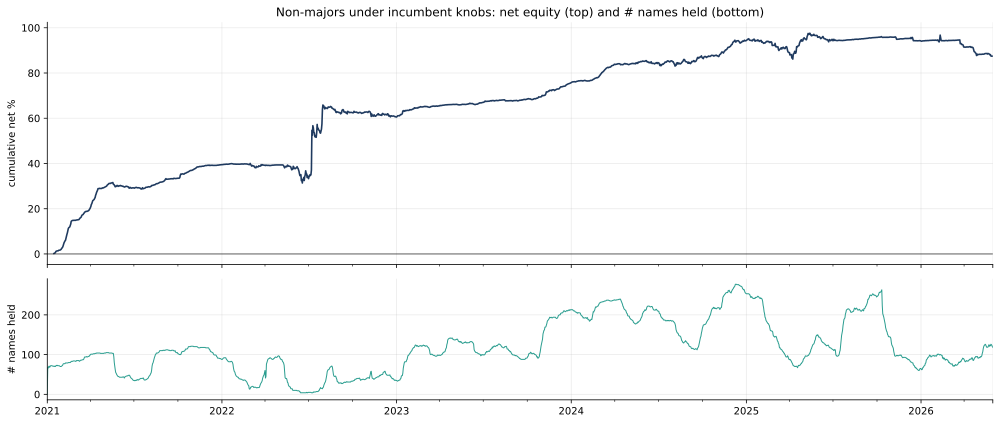

avg names held: 119.2 | days deployed: 100% | turnover 15x/yr


In [8]:
# What the broad universe actually does under the incumbent: names held + net equity over time
_,rn = kpi(Pnon, INC, mn())
fig, (a1,a2) = plt.subplots(2,1,figsize=(14,6),sharex=True,gridspec_kw={'height_ratios':[2,1]})
(rn['net'].cumsum()*100).plot(ax=a1,color=NAVY,lw=1.6); a1.axhline(0,color='k',lw=0.6)
a1.set_ylabel('cumulative net %'); a1.set_title('Non-majors under incumbent knobs: net equity (top) and # names held (bottom)')
rn['deployed'].reindex(Pnon['didx']).plot(ax=a2,color=TEAL,lw=1.0); a2.set_ylabel('# names held')
plt.tight_layout(); plt.show()
print(f"avg names held: {rn['1.0x']['avg_names_held']:.1f} | days deployed: {rn['1.0x']['pct_days_deployed']:.0%} | turnover {rn['1.0x']['ann_turnover']:.0f}x/yr")

## Axis 3 — strictest: unseen names *and* unseen time

Apply the incumbent, and the temporally-tuned `best_T`, to the **non-majors over 2024–2026** — names
the knobs never saw, in a period they never saw.

In [9]:
rows={}
for lab,knob in [('incumbent',INC),('best_T (temporal-tuned)',BEST_T),('best_C (xsec-tuned)',BEST_C)]:
    rows[lab],_ = kpi(Pnon, knob, mn(start='2024-01-01'))
print('Non-majors, 2024-2026 (unseen names + unseen time):')
print(pd.DataFrame(rows).T.to_string())

Non-majors, 2024-2026 (unseen names + unseen time):
                         net_apr%  net_apr_2x%  sharpe  sharpe_2x  gross_apr%  max_dd%  turnover  pct_deployed  avg_names
incumbent                    4.93         2.68   0.867      0.472        7.17     -9.8      11.8           1.0     162.96
best_T (temporal-tuned)      1.94         0.75   0.278      0.107        3.13    -17.9       6.3           1.0     147.55
best_C (xsec-tuned)          1.94         0.75   0.278      0.107        3.13    -17.9       6.3           1.0     147.55


## Verdict

In [10]:
# Data-driven summary: does the incumbent survive OOS, and how big is the optimism gap?
def net_sh(panels,knob,msk):
    r=H.evaluate(panels,knob['ewma_halflife'],knob['theta_in_apr'],knob['theta_keep_apr'],COSTS,mask=msk)
    return r['1.0x']['ann_return'], r['1.0x']['sharpe'], r['2.0x']['ann_return']
maj_is  = net_sh(Pmaj, INC, m())
maj_oos = net_sh(Pmaj, INC, m(start='2024-01-01'))
non_oos = net_sh(Pnon, INC, mn())
non_late= net_sh(Pnon, INC, mn(start='2024-01-01'))
print(f"INCUMBENT (8%/2%/7d):")
print(f"  majors full   : net {maj_is[0]:+.1%}  Sharpe {maj_is[1]:.2f}  net@2x {maj_is[2]:+.1%}")
print(f"  majors OOS    : net {maj_oos[0]:+.1%}  Sharpe {maj_oos[1]:.2f}  net@2x {maj_oos[2]:+.1%}")
print(f"  non-majors    : net {non_oos[0]:+.1%}  Sharpe {non_oos[1]:.2f}  net@2x {non_oos[2]:+.1%}")
print(f"  non-maj + late: net {non_late[0]:+.1%}  Sharpe {non_late[1]:.2f}  net@2x {non_late[2]:+.1%}")
gate = lambda x: (x[0]>0) and (x[2]>0)
print(f"\n  clears gate (net>0 & net@2x>0) on all four splits: {all(gate(x) for x in [maj_is,maj_oos,non_oos,non_late])}")
print(f"  Sharpe majors→non-majors decay: {maj_is[1]:.1f} -> {non_oos[1]:.1f}  ({non_oos[1]/maj_is[1]-1:+.0%})")

INCUMBENT (8%/2%/7d):
  majors full   : net +9.4%  Sharpe 6.41  net@2x +7.7%
  majors OOS    : net +5.8%  Sharpe 7.40  net@2x +4.6%
  non-majors    : net +16.3%  Sharpe 1.57  net@2x +13.4%
  non-maj + late: net +4.9%  Sharpe 0.87  net@2x +2.7%

  clears gate (net>0 & net@2x>0) on all four splits: True
  Sharpe majors→non-majors decay: 6.4 -> 1.6  (-76%)


**Read the tables + scatters, but the shape we expect:**

- **Temporal (majors):** the incumbent should still clear the gate on 2024–2026, at a lower Sharpe
  than in-sample — that decay is the honest cost of having tuned on the sample. If the train→test
  scatter has *positive* correlation and the incumbent star sits near the diagonal, the knobs are
  robust across time (not fit to noise). The re-tuned `best_T` typically wins in-sample and gives
  back most of the edge out-of-sample — evidence that chasing the top-Sharpe knob is overfitting.
- **Cross-sectional:** the majors' Sharpe (~6) does **not** carry to the 461-name tail (expect
  ~1–2) with higher turnover — the majors are exceptionally clean carry, not a representative sample.
  Net stays positive, which is the real, scalable result; the majors number was flattering.
- **Strictest (unseen names + time):** the number to quote as the defensible expectation.

**Takeaway for the build:** don't trust the 6.4 Sharpe — quote the cross-sectional / strict-OOS
figure. The incumbent knobs are a *reasonable, robust* setting (they were never finely tuned), so
keep them for v1; the real lever is not re-tuning θ/halflife on 5 names but the **v2 selection +
health/liquidity veto** on the full universe, where the broad-universe turnover and dispersion (seen
above) actually live. Caveats: gross-of-slippage-capacity; equal-weight the whole band (no top-K);
'best' knobs are still chosen on one tuning set — the scatter, not the single star, is the evidence.